# Taxi Traffic NYC

**Auteur :** Matis Boudelier  
**Date :** 2026-11-05

### Chargement des packages

In [54]:
library(fda)
library(tidyfun)
library(viridis)
library(tidyverse)
library(RColorBrewer)
library(mosaicData)


Dans ce projet d'analyse de données fonctionnelles, nous allons étudiés le jeu de données NYC Taxi Traffic provenant
de la Commission des taxis et limousines de New York et répertoriant le nombre total de passagers de taxi par tranches de 30 minutes,
de minuit à 23h30 (48 points de calcul), chaque jour, du 1er Juillet 2014 au 31 Janvier 2015 (250 jours au total).

## Chargement des données


In [55]:
df = read_csv("TaxiTraffic.csv")

colSums(is.na(df))
# Aucune valeur manquante

length(unique(as.Date(df$timestamp)))
# 215 jours analysés

New names:
• `` -> `...1`
Rows: 10320 Columns: 3
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl  (2): ...1, value
dttm (1): timestamp

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


...1 timestamp     value 
        0         0         0

[1] 215

Il n'y a que 2 variables (intéressantes) :
- `timestamp` : La date et l'horaire (chaque demi-heure) de la course 
- `value` : Le nombre de passagers dans toute la ville à cette date-horaire


## Nettoyage

- Séparation de la variable `timestamp` en `Year`, `Month`, `Day` et `Hour`.
- Ajout de l'heure '00:00:00' aux lignes correspondantes car le chargement des données a transformé la valeur en NA.

Pour faciliter les analyses et graphiques :
- Ajout de la variable `Hour_posix` pour avoir la vraie heure chronologique.
- Ajout de la variable `Month_char` avec les noms des mois en variable catégorielles.
- Transformation des variable `Year`, `Month` et `Day` en variables catégorielles.

In [56]:
data <- df |>
  select(-`...1`) |>
  separate(col = `timestamp`, into = c("Date", "Hour"), sep = " ", fill="right") |>
  mutate(
    Month_char = format(as.Date(Date), "%B")
  ) |>
  separate(col = `Date`, into = c("Year", "Month", "Day"), sep = "-") |>
  mutate(
    Hour = if_else(is.na(Hour) | Hour == "", "00:00:00", Hour)
  )

data$Hour_posix <- as.POSIXct(paste("1970-01-01", data$Hour), format = "%Y-%m-%d %H:%M:%S")

data$Year <- as.factor(data$Year)
data$Month <- as.factor(data$Month)
mois_ordre <- c("juillet", "août", "septembre", "octobre", "novembre", "décembre", "janvier")
data$Month_char <- factor(data$Month_char, levels = mois_ordre)
data$Day <- as.factor(data$Day)

In [57]:
summary(data)

   Year      Month          Day              Hour           value      
 2014:8832   01:1488   01     : 336   Length   :10320   Min.   :    8  
 2015:1488   07:1488   02     : 336   N.unique :   48   1st Qu.:10262  
             08:1488   03     : 336   N.blank  :    0   Median :16778  
             09:1440   04     : 336   Min.nchar:    8   Mean   :15138  
             10:1488   05     : 336   Max.nchar:    8   3rd Qu.:19839  
             11:1440   06     : 336                     Max.   :39197  
             12:1488   (Other):8304                                    
     Month_char     Hour_posix                 
 juillet  :1488   Min.   :1970-01-01 00:00:00  
 août     :1488   1st Qu.:1970-01-01 05:52:30  
 septembre:1440   Median :1970-01-01 11:45:00  
 octobre  :1488   Mean   :1970-01-01 11:45:00  
 novembre :1440   3rd Qu.:1970-01-01 17:37:30  
 décembre :1488   Max.   :1970-01-01 23:30:00  
 janvier  :1488                                

In [58]:
head(data)
dim(data)

Year,Month,Day,Hour,value,Month_char,Hour_posix
<fct>,<fct>,<fct>,<chr>,<dbl>,<fct>,<dttm>
2014,07,01,00:00:00,10844,juillet,1970-01-01 00:00:00
2014,07,01,00:30:00,8127,juillet,1970-01-01 00:30:00
2014,07,01,01:00:00,6210,juillet,1970-01-01 01:00:00
2014,07,01,01:30:00,4656,juillet,1970-01-01 01:30:00
2014,07,01,02:00:00,3820,juillet,1970-01-01 02:00:00
2014,07,01,02:30:00,2873,juillet,1970-01-01 02:30:00


[1] 10320     7

## Graphiques de présentation

### 1.Affichage d'une journée

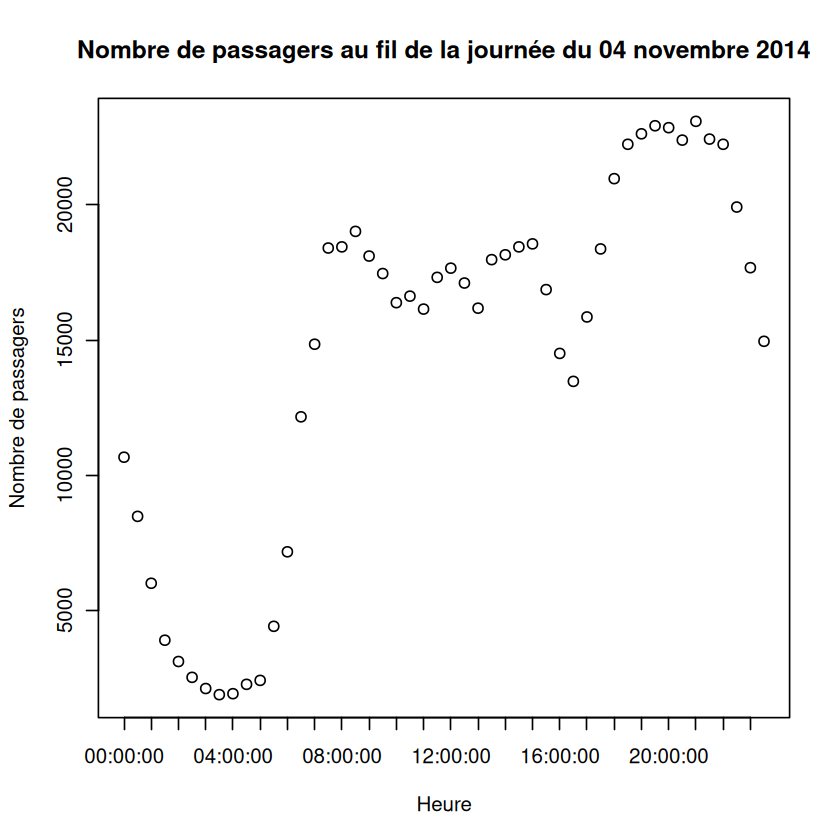

In [59]:
i <- 127
day_start <- 1+(i-1)*48
day_end <- i*48
day <- data[day_start:day_end,]
plot(day$Hour_posix, day$value, xaxt = "n", xlab = "Heure", ylab = "Nombre de passagers")
axis.POSIXct(1, at = seq(min(day$Hour_posix), max(day$Hour_posix), by = "1 hour"), format = "%H:%M:%S")
title(paste("Nombre de passagers au fil de la journée du", day$Day[1], day$Month_char[1], day$Year[1]))

Nous avons bien des données fonctionnelles pour chaque journée avec des valeurs hétérogènes au fil des heures.
Il sera intéressant de comparer les journées en fonction du nombre de passagers sur des tranches horaires (entre minuit et 6h puis entre 6h et 16h
et entre 16h et minuit). Regardons maintenant sur toutes les journées.

### 2.Couleur par jour

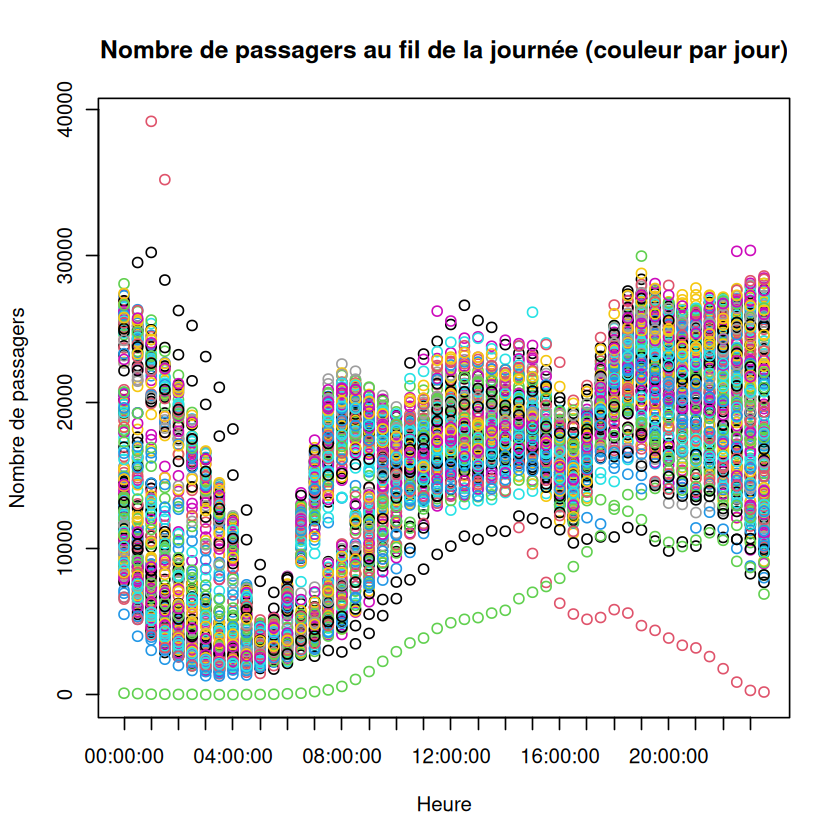

In [60]:
colors_day <- as.numeric(data$Day)
#plot(data$Hour_posix[1:48], data$value[1:48], col=colors[1:48])


plot(data$Hour_posix, data$value, col = colors_day, xaxt = "n", xlab = "Heure", ylab = "Nombre de passagers")
axis.POSIXct(1, at = seq(min(data$Hour_posix), max(data$Hour_posix), by = "1 hour"), format = "%H:%M:%S")
title("Nombre de passagers au fil de la journée (couleur par jour)")

On remarque une forme partagée par le majorité des journées :
Il semble y avoir plus de personnes qui prend un taxi l'après-midi (entre 12h et 20h) que le reste de la journée.
Comparons, si possible par mois.

CHUNCK SUIVANT PEUT-ÊTRE A ENLEVER 
### 3.Couleur par mois

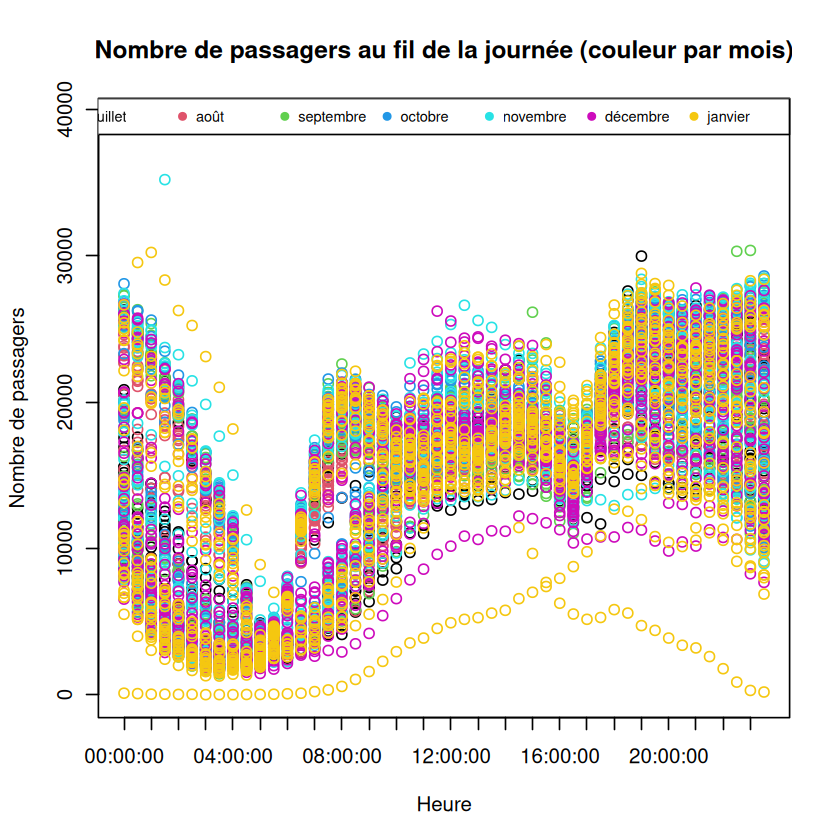

In [61]:
plot(data$Hour_posix, data$value, col = data$Month_char, xaxt = "n", xlab = "Heure", ylab = "Nombre de passagers")
axis.POSIXct(1, at = seq(min(data$Hour_posix), max(data$Hour_posix), by = "1 hour"), format = "%H:%M:%S")
legend("topright",                                     # Position ("topright", "bottomleft", "center", etc.)
       legend = levels(data$Month_char),        # Le texte des catégories
       col = seq_along(levels(data$Month_char)),# Les couleurs utilisées
       pch = 19,
       horiz = TRUE,                          # <-- MET LA LÉGENDE À L'HORIZONTALE
       cex = 0.7
       )
title("Nombre de passagers au fil de la journée (couleur par mois)")

### Graphique pour chaque mois

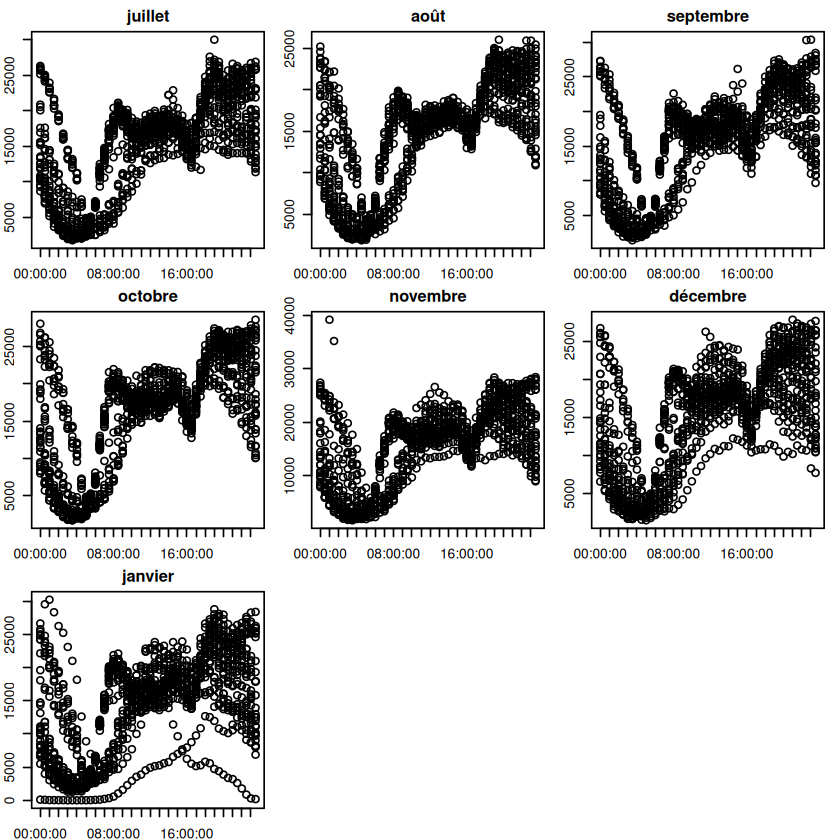

In [62]:
# Diviser la fenêtre graphique en une grille (3 lignes x 4 colonnes)
par(mfrow = c(3, 3), mar = c(2, 2, 2, 1))

for (m in levels(data$Month_char)) {
  
  # Filtrer les données pour le mois en cours
  subset_data <- subset(data, Month_char == m)
  
  # Tracer le graphique du mois (seulement s'il y a des données)
  if(nrow(subset_data) > 0) {
    plot(subset_data$Hour_posix,
         subset_data$value,
         main = m,             # Titre avec le nom du mois
         xlab = "Heure", ylab = "Nombre de passagers",
         xaxt = "n")
    axis.POSIXct(1, at = seq(min(data$Hour_posix), max(data$Hour_posix), by = "1 hour"), format = "%H:%M:%S")
  }
}

# 3. Remettre l'affichage graphique par défaut (1 seul graphique par écran)
par(mfrow = c(1, 1))

A première vue, on peut voir une forme similaire pour la majorité de chaque journée de chaque mois mais avec une petite baisse globalesur les mois d'hiver. Ce sera une analyse intéressante à faire dans ce projet.

Commençons par un lissage des données par Moindres Carrés pénalisés.

## Lissage par Moindres Carrés pénalisés

### Du tableau à l'objet fonctionnel

Jusqu'ici les données sont stockées en format long, une ligne = un relevé. Pour l'analyse fonctionnelle il nous faut une matrice 48 × 215 : une colonne par journée, une ligne par instant de la journée. Chaque colonne est alors une courbe $X_i(t)$, $t \in [0,24]$.

In [72]:
# Reconstruction d'une date complète et d'une heure numérique (0 ; 0,5 ; ... ; 23,5)
data_fd <- data |>
  mutate(
    Date  = as.Date(paste(Year, Month, Day, sep = "-")),
    heure = as.numeric(substr(Hour, 1, 2)) + as.numeric(substr(Hour, 4, 5)) / 60
  )

mat <- data_fd |>
  select(Date, heure, value) |>
  pivot_wider(names_from = Date, values_from = value) |>
  arrange(heure)

heures <- mat$heure                 # grille : 0, 0.5, ..., 23.5
Y      <- as.matrix(mat[, -1])      # 48 instants x 215 jours
jours  <- as.Date(colnames(Y))

dim(Y)


[1]  48 215

In [64]:
# Jour de la semaine ($wday : 0 = dimanche ... 6 = samedi, indépendant de la langue)
wday     <- as.POSIXlt(jours)$wday
week_end <- wday %in% c(0, 6)
table(ifelse(week_end, "week-end", "semaine"))


 semaine week-end 
     154       61 

### Principe

Chaque journée n'est observée qu'en 48 instants. Pour obtenir une vraie fonction $X_i(t)$ définie sur tout $[0,24]$, on la développe dans une base et on estime les coefficients par
moindres carrés pénalisés.

### Choix de la base : Fourier plutôt que B-splines

Le cours lisse les températures canadiennes avec des B-splines. Ici le phénomène est périodique,minuit d'une journée se raccorde à minuit de la journée suivante, donc on doit avoir $X_i(0) = X_i(24)$. Les B-splines n'imposent pas cette contrainte, la base de Fourier si.

### Choix de $\lambda$ par validation croisée généralisée (GCV)

In [65]:
NBASIS <- 21
base_f <- create.fourier.basis(rangeval = c(0, 24), nbasis = NBASIS)

lambdas <- 10^seq(-6, 4, by = 0.25)
gcv_tot <- sapply(lambdas, function(l) {
  fdP <- fdPar(base_f, Lfdobj = 2, lambda = l)
  sum(smooth.basis(heures, Y, fdP)$gcv)
})

lambda_opt <- lambdas[which.min(gcv_tot)]
lambda_opt

[1] 0.03162278

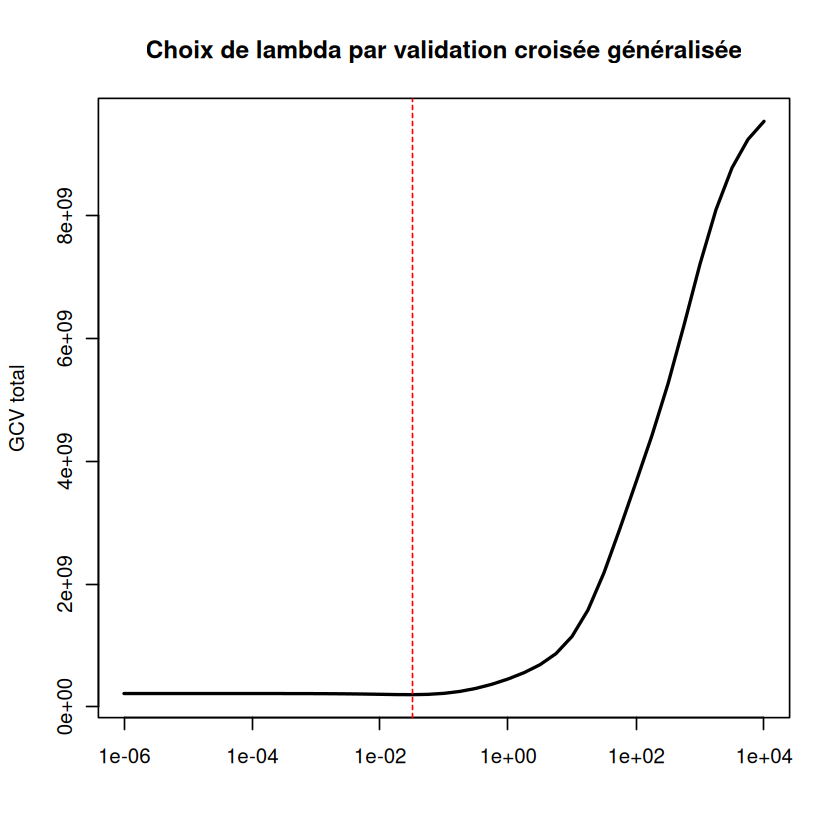

In [66]:
plot(lambdas, gcv_tot, log = "x", type = "l", lwd = 2,
     xlab = expression(lambda), ylab = "GCV total",
     main = "Choix de lambda par validation croisée généralisée")
abline(v = lambda_opt, col = "red", lty = 2)

In [67]:
fdPar_opt <- fdPar(base_f, Lfdobj = 2, lambda = lambda_opt)
lissage   <- smooth.basis(heures, Y, fdPar_opt)
taxi_fd   <- lissage$fd

# degrés de liberté effectifs
mean(lissage$df) 

[1] 18.40695

On obtient $\lambda_{opt} \approx 3{,}2\times 10^{-2}$, soit environ 18,4 degrés de liberté effectifs pour 48 points par courbe, le lissage conserve la structure journalière tout en absorbant le bruit.

### Effet du paramètre de lissage

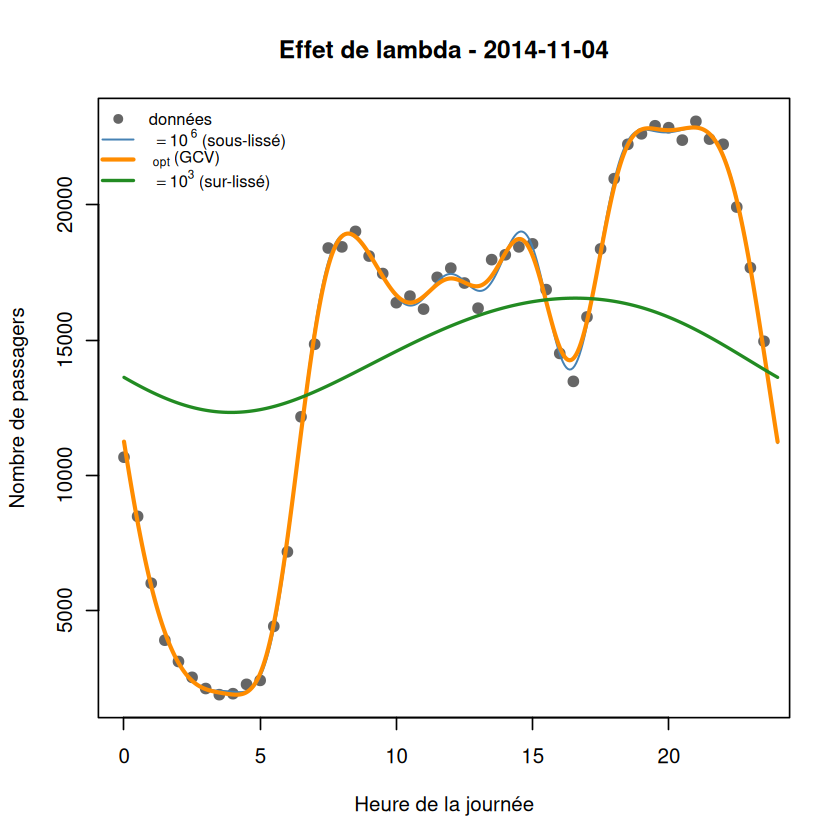

In [68]:
i <- 127                   
gr <- seq(0, 24, length.out = 400)

fd_sous <- smooth.basis(heures, Y, fdPar(base_f, 2, 1e-6))$fd
fd_sur  <- smooth.basis(heures, Y, fdPar(base_f, 2, 1e3))$fd

plot(heures, Y[, i], pch = 19, col = "grey40",
     xlab = "Heure de la journée", ylab = "Nombre de passagers",
     main = paste("Effet de lambda -", jours[i]))
lines(gr, eval.fd(gr, fd_sous[i]), col = "steelblue", lwd = 1.2)
lines(gr, eval.fd(gr, taxi_fd[i]),  col = "darkorange", lwd = 2.5)
lines(gr, eval.fd(gr, fd_sur[i]),   col = "forestgreen", lwd = 2)
legend("topleft", bty = "n", cex = 0.8,
       legend = c("données", expression(lambda == 10^-6~"(sous-lissé)"),
                  expression(lambda[opt]~"(GCV)"), expression(lambda == 10^3~"(sur-lissé)")),
       col = c("grey40", "steelblue", "darkorange", "forestgreen"),
       pch = c(19, NA, NA, NA), lty = c(NA, 1, 1, 1), lwd = c(NA, 1.2, 2.5, 2))

### Résultat

[1] "done"

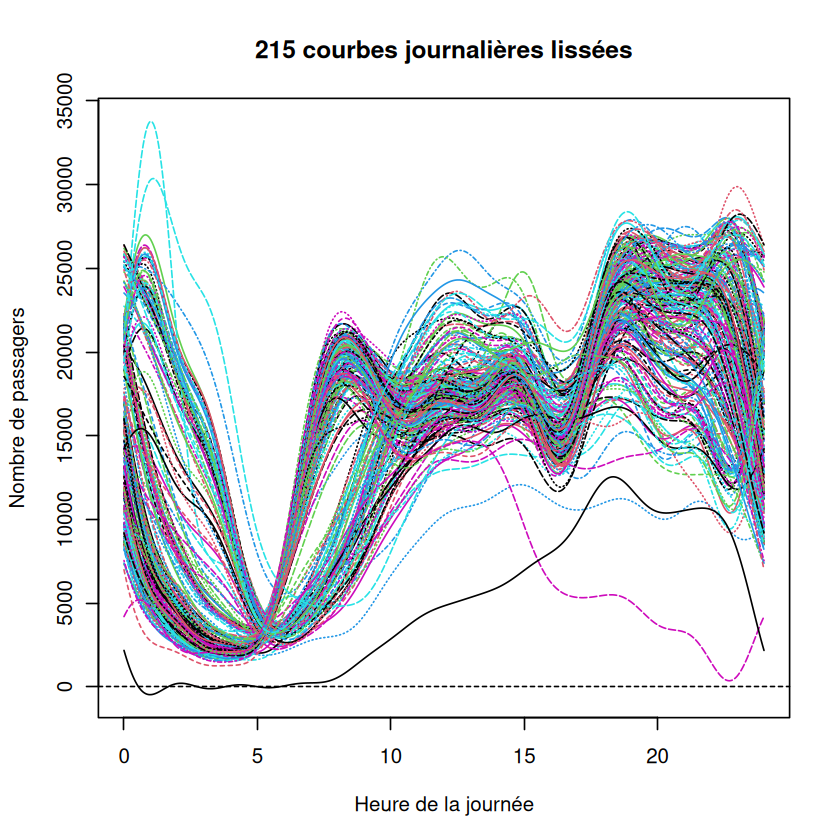

In [69]:
plot(taxi_fd, xlab = "Heure de la journée", ylab = "Nombre de passagers",
     main = "215 courbes journalières lissées")

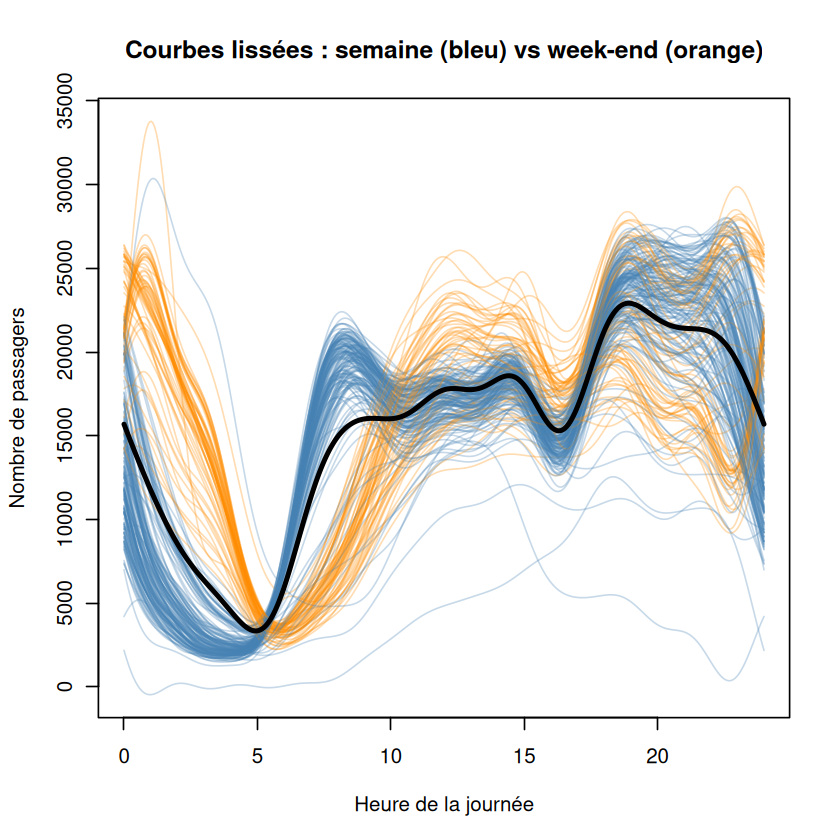

In [70]:
# Les mêmes courbes, colorées semaine / week-end
matplot(gr, eval.fd(gr, taxi_fd), type = "l", lty = 1,
        col = adjustcolor(ifelse(week_end, "darkorange", "steelblue"), 0.3),
        xlab = "Heure de la journée", ylab = "Nombre de passagers",
        main = "Courbes lissées : semaine (bleu) vs week-end (orange)")
lines(gr, rowMeans(eval.fd(gr, taxi_fd)), lwd = 3)

Le lissage fait ressortir les motifs qui seront exploités dans la suite : creux nocturne vers 5h, pic de navette matinal marqué en semaine, plateau d'après-midi et pic du soir. Les week-ends se distinguent déjà nettement par une activité nocturne prolongée et l'absence de pic matinal.